# 02 · Réplica del análisis del artículo

Tablas 4 y 9 de Chicco & Jurman (2020) sobre el dato real y el simulado, con 100 particiones por modelo y la misma semilla por partición en ambos datasets.

## Configuración

In [1]:
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import parametros as P
from src.simulacion import simular
from src.fidelidad import cargar_real
from src.modelos import replicar_tabla4, replicar_tabla9, resumir, comparar, METRICAS

pd.set_option("display.width", 200, "display.max_columns", 30)

real = cargar_real()
sim = simular(random_state=42)

## Tabla 4: 10 clasificadores con las 11 variables clínicas

In [2]:
inicio = time.time()

print("Dataset REAL")
res4_real = replicar_tabla4(real, n_rep=100)
print("Dataset SIMULADO")
res4_sim = replicar_tabla4(sim, n_rep=100)

print(f"\nTiempo total: {(time.time() - inicio) / 60:.1f} min")

res4_real.to_csv("results/tabla4_real_100rep.csv", index=False)
res4_sim.to_csv("results/tabla4_sim_100rep.csv", index=False)

t4_real = resumir(res4_real)
t4_sim = resumir(res4_sim)
comp4 = comparar(P.PAPER_TABLA4, t4_real, t4_sim, metrica="MCC")
comp4.to_csv("results/comparacion_tabla4_MCC.csv")
print(comp4.to_string())

Dataset REAL
  repetición 10/100
  repetición 20/100
  repetición 30/100
  repetición 40/100
  repetición 50/100
  repetición 60/100
  repetición 70/100
  repetición 80/100
  repetición 90/100
  repetición 100/100
Dataset SIMULADO
  repetición 10/100
  repetición 20/100
  repetición 30/100
  repetición 40/100
  repetición 50/100
  repetición 60/100
  repetición 70/100
  repetición 80/100
  repetición 90/100
  repetición 100/100

Tiempo total: 3.1 min
                           paper   real  simulado  real - paper  sim - real
Random forests             0.384  0.368     0.363        -0.016      -0.005
Decision tree              0.376  0.339     0.238        -0.037      -0.101
Gradient boosting          0.367  0.347     0.277        -0.020      -0.070
Linear regression          0.332  0.357     0.378         0.025       0.021
One rule                   0.319  0.282     0.164        -0.037      -0.118
Artificial neural network  0.262  0.282     0.253         0.020      -0.029
Naive bayes  

## Diagnóstico: efecto de la estandarización en kNN y SVM lineal

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef, recall_score
from src.modelos import VARIABLES_CLINICAS

X = real[VARIABLES_CLINICAS].to_numpy(float)
y = real["DEATH_EVENT"].to_numpy(int)

variantes = {
    "kNN k=3 SIN escalar": KNeighborsClassifier(n_neighbors=3),
    "kNN k=3 CON escalar": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
    "SVM lineal C=0.1 SIN escalar": SVC(kernel="linear", C=0.1, max_iter=200000),
    "SVM lineal C=0.1 CON escalar": make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.1)),
}

filas = []
for nombre, modelo in variantes.items():
    mcc, tpr = [], []
    for rep in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42 + rep)
        pred = modelo.fit(X_tr, y_tr).predict(X_te)
        mcc.append(matthews_corrcoef(y_te, pred))
        tpr.append(recall_score(y_te, pred))
    filas.append({"variante": nombre, "MCC": np.mean(mcc), "TPR": np.mean(tpr)})

diag_escalado = pd.DataFrame(filas).round(3)
diag_escalado.to_csv("results/diagnostico_escalado.csv", index=False)
print(diag_escalado.to_string(index=False))

                    variante    MCC   TPR
         kNN k=3 SIN escalar -0.005 0.229
         kNN k=3 CON escalar  0.162 0.272
SVM lineal C=0.1 SIN escalar -0.031 0.502
SVM lineal C=0.1 CON escalar  0.359 0.374


## Tabla 9: creatinina + fracción de eyección; prueba de H1 y H2

In [4]:
inicio = time.time()
res9_real = replicar_tabla9(real, n_rep=100)
res9_sim = replicar_tabla9(sim, n_rep=100)
print(f"Tiempo: {(time.time() - inicio) / 60:.1f} min\n")

res9_real.to_csv("results/tabla9_real_100rep.csv", index=False)
res9_sim.to_csv("results/tabla9_sim_100rep.csv", index=False)

t9_real = resumir(res9_real)
t9_sim = resumir(res9_sim)
comp9 = comparar(P.PAPER_TABLA9, t9_real, t9_sim, metrica="MCC")
comp9.to_csv("results/comparacion_tabla9_MCC.csv")
print("=== Tabla 9: MCC con creatinina + fracción de eyección ===")
print(comp9.to_string())

modelos_comunes = ["Random forests", "Gradient boosting", "SVM radial"]
hipotesis = pd.DataFrame({
    "brecha 11 variables (T4)": (t4_sim.loc[modelos_comunes, "MCC"] - t4_real.loc[modelos_comunes, "MCC"]),
    "brecha 2 variables (T9)": (t9_sim.loc[modelos_comunes, "MCC"] - t9_real.loc[modelos_comunes, "MCC"]),
}).round(3)
hipotesis["H1: sim < real en T9"] = hipotesis["brecha 2 variables (T9)"] < 0
hipotesis["H2: brecha T9 mayor"] = hipotesis["brecha 2 variables (T9)"] < hipotesis["brecha 11 variables (T4)"]
hipotesis.to_csv("results/prueba_hipotesis_H1_H2.csv")
print("\n=== Prueba de hipótesis ===")
print(hipotesis.to_string())

Tiempo: 0.9 min

=== Tabla 9: MCC con creatinina + fracción de eyección ===
                   paper   real  simulado  real - paper  sim - real
Random forests     0.418  0.404     0.207        -0.014      -0.197
Gradient boosting  0.414  0.395     0.174        -0.019      -0.221
SVM radial         0.348  0.338     0.291        -0.010      -0.047

=== Prueba de hipótesis ===
                   brecha 11 variables (T4)  brecha 2 variables (T9)  H1: sim < real en T9  H2: brecha T9 mayor
modelo                                                                                                         
Random forests                       -0.005                   -0.197                  True                 True
Gradient boosting                    -0.070                   -0.221                  True                 True
SVM radial                            0.043                   -0.047                  True                 True


## Significancia estadística y ROC AUC

In [5]:
from scipy import stats

filas = []
for m in ["Random forests", "Gradient boosting", "SVM radial"]:
    t9r = res9_real.loc[res9_real.modelo == m, "MCC"].to_numpy()
    t9s = res9_sim.loc[res9_sim.modelo == m, "MCC"].to_numpy()
    t4r = res4_real.loc[res4_real.modelo == m, "MCC"].to_numpy()
    filas.append({
        "modelo": m,
        "T9 real (media ± sd)": f"{t9r.mean():.3f} ± {t9r.std():.3f}",
        "T9 sim (media ± sd)": f"{t9s.mean():.3f} ± {t9s.std():.3f}",
        "p real vs sim (Wilcoxon pareado)": stats.wilcoxon(t9r, t9s).pvalue,
        "T4 real (media)": round(t4r.mean(), 3),
        "p 2 var vs 11 var, real (Mann-Whitney)": stats.mannwhitneyu(t9r, t4r).pvalue,
    })

significancia = pd.DataFrame(filas).set_index("modelo")
significancia.to_csv("results/significancia_tabla9.csv")
print(significancia.to_string(float_format=lambda x: f"{x:.2e}"))

auc_comp = pd.DataFrame({
    "ROC_AUC 11 var (real)": t4_real.loc[["Random forests", "Gradient boosting", "SVM radial"], "ROC_AUC"],
    "ROC_AUC 2 var (real)": t9_real["ROC_AUC"],
    "ROC_AUC 2 var (paper)": {m: v["ROC_AUC"] for m, v in P.PAPER_TABLA9.items()},
}).round(3)
print("\n", auc_comp.to_string())

                  T9 real (media ± sd) T9 sim (media ± sd)  p real vs sim (Wilcoxon pareado)  T4 real (media)  p 2 var vs 11 var, real (Mann-Whitney)
modelo                                                                                                                                               
Random forests           0.404 ± 0.082       0.207 ± 0.082                          2.49e-17         3.68e-01                                4.88e-02
Gradient boosting        0.395 ± 0.086       0.174 ± 0.092                          2.02e-17         3.47e-01                                6.50e-04
SVM radial               0.338 ± 0.092       0.291 ± 0.091                          2.28e-03         2.89e-01                                1.29e-03

                    ROC_AUC 11 var (real)  ROC_AUC 2 var (real)  ROC_AUC 2 var (paper)
Random forests                     0.791                 0.792                  0.698
Gradient boosting                  0.737                 0.780              

## Figura comparativa

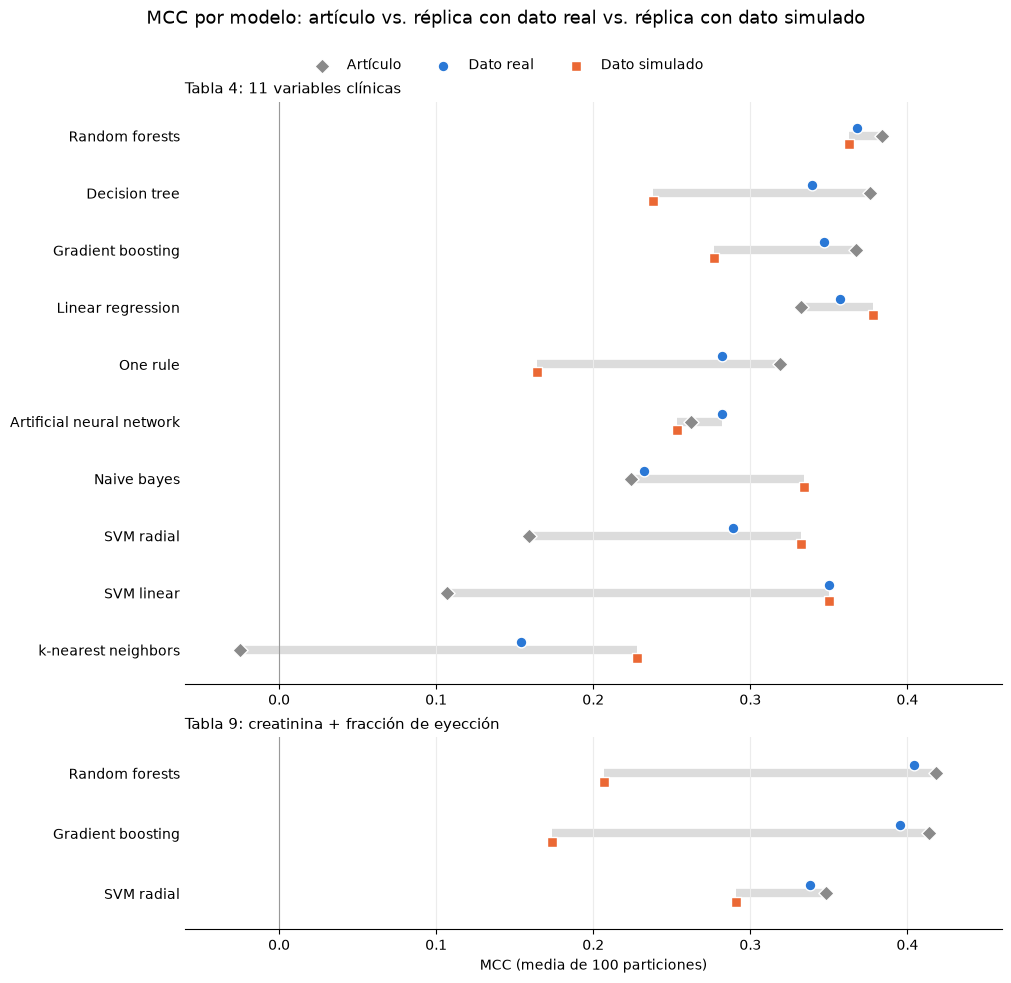

In [6]:
FUENTES = {"Artículo": "#8a8a8a", "Dato real": "#2a78d6", "Dato simulado": "#eb6834"}
MARCAS = {"Artículo": "D", "Dato real": "o", "Dato simulado": "s"}
DESPLAZAMIENTO = {"Artículo": 0.0, "Dato real": 0.14, "Dato simulado": -0.14}

def panel(ax, paper, real, sim, titulo):
    orden = sorted(paper, key=lambda m: paper[m]["MCC"])
    y = np.arange(len(orden))
    valores = {
        "Artículo": [paper[m]["MCC"] for m in orden],
        "Dato real": [real.loc[m, "MCC"] for m in orden],
        "Dato simulado": [sim.loc[m, "MCC"] for m in orden],
    }
    for i in y:
        fila = [valores[f][i] for f in FUENTES]
        ax.hlines(i, min(fila), max(fila), color="#dcdcdc", lw=6, zorder=1)
    for fuente, color in FUENTES.items():
        ax.scatter(valores[fuente], y + DESPLAZAMIENTO[fuente], s=60, color=color,
                   marker=MARCAS[fuente], label=fuente, zorder=3, edgecolor="white", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(orden)
    ax.set_ylim(-0.6, len(orden) - 0.4)
    ax.set_xlim(-0.06, 0.46)
    ax.axvline(0, color="#999", lw=0.8)
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.grid(axis="x", color="#ececec")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9), constrained_layout=True,
                               gridspec_kw={"height_ratios": [10, 3.3]})
panel(ax1, P.PAPER_TABLA4, t4_real, t4_sim, "Tabla 4: 11 variables clínicas")
panel(ax2, P.PAPER_TABLA9, t9_real, t9_sim, "Tabla 9: creatinina + fracción de eyección")
ax2.set_xlabel("MCC (media de 100 particiones)")
fig.legend(*ax1.get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.035))
fig.suptitle("MCC por modelo: artículo vs. réplica con dato real vs. réplica con dato simulado",
             fontsize=13, y=1.075)
fig.savefig("figures/02_comparacion_mcc.png", dpi=150, bbox_inches="tight")
plt.show()